## Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Importing libraries and configure memory

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout, Rescaling
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix
# Clear previous Keras models
tf.keras.backend.clear_session()
# Enable GPU memory growth if GPU is available
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)
print("TensorFlow version:", tf.__version__)
print("Available GPU:", gpus)

TensorFlow version: 2.21.0
Available GPU: []


## Define dataset path

In [3]:
maindata = '/content/drive/MyDrive/DL/CNN/tomato_leaf_diseases'
train_path = os.path.join(maindata, 'train')
val_path = os.path.join(maindata, 'val')
IMG_SIZE = (150, 150)
BATCH_SIZE = 8
print("Training path exists:", os.path.exists(train_path))
print("Validation path exists:", os.path.exists(val_path))
print("Training folders:", sorted(os.listdir(train_path)))
print("Validation folders:", sorted(os.listdir(val_path)))

Training path exists: True
Validation path exists: True
Training folders: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']
Validation folders: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']


## Load images in batches

In [4]:
# Load training images
train_ds = tf.keras.utils.image_dataset_from_directory(train_path,image_size=IMG_SIZE,batch_size=BATCH_SIZE,
    color_mode='rgb',label_mode='int',shuffle=True,seed=42)
# Get class names
class_names = train_ds.class_names
# Load validation images
val_ds = tf.keras.utils.image_dataset_from_directory(val_path,image_size=IMG_SIZE,batch_size=BATCH_SIZE,color_mode='rgb',
    label_mode='int',class_names=class_names,shuffle=False)
num_classes = len(class_names)
print("Disease classes:", class_names)
print("Total classes:", num_classes)

Found 10004 files belonging to 10 classes.
Found 984 files belonging to 10 classes.
Disease classes: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']
Total classes: 10


## Optimize dataset loading

In [5]:
# Limit background processing
options = tf.data.Options()
options.threading.private_threadpool_size = 2
options.threading.max_intra_op_parallelism = 1
train_ds = train_ds.with_options(options).prefetch(1)
val_ds = val_ds.with_options(options).prefetch(1)

## Check image shape and display sample images

Image batch shape: (8, 150, 150, 3)
Label batch shape: (8,)
Image data type: <dtype: 'float32'>


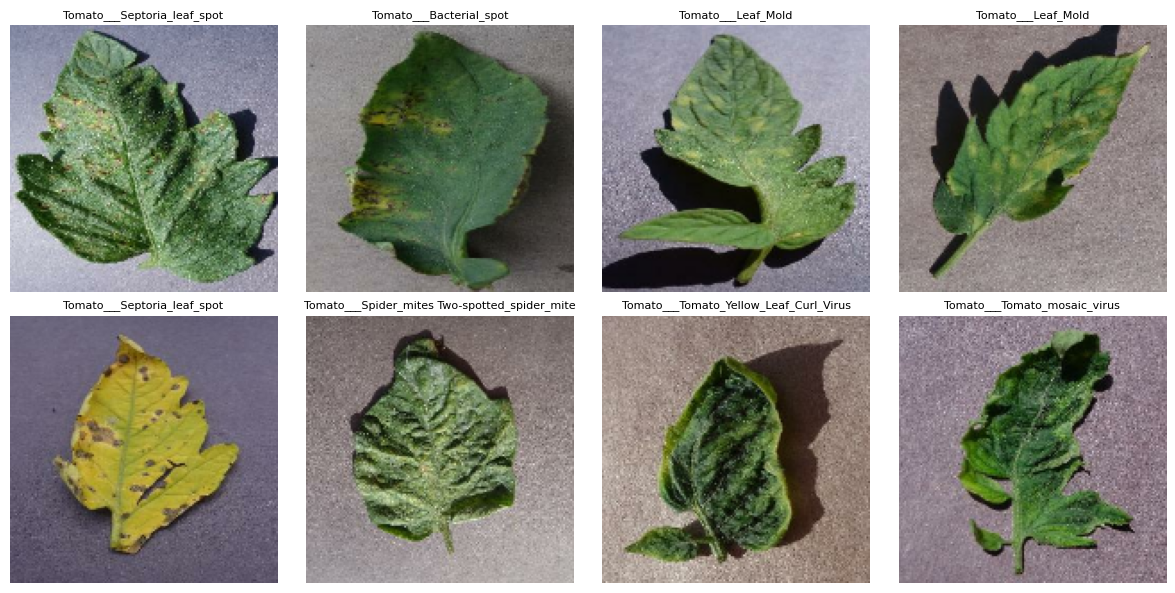

In [6]:
images, labels = next(iter(train_ds))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
plt.figure(figsize=(12, 6))
for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy().astype('uint8'))
    plt.title(class_names[labels[i].numpy()], fontsize=8)
    plt.axis('off')

plt.tight_layout()
plt.show()

## Class distribution

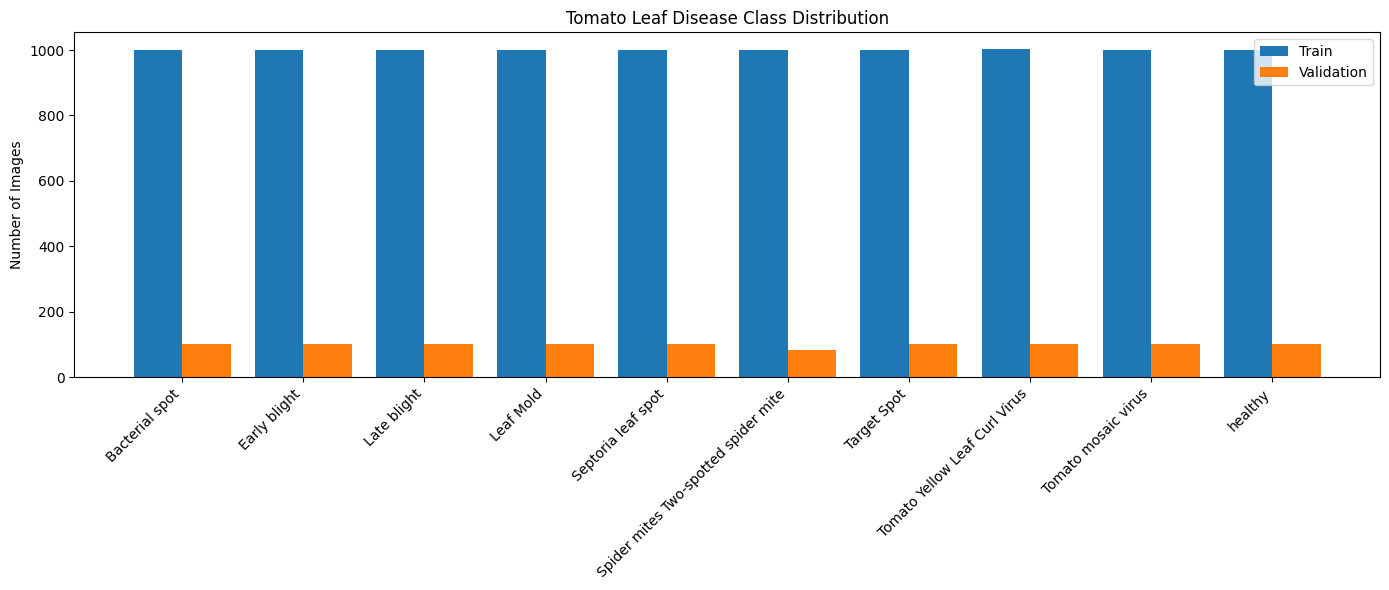

In [7]:
extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.gif')
train_counts = []
val_counts = []
for category in class_names:
    train_folder = os.path.join(train_path, category)
    val_folder = os.path.join(val_path, category)
    train_count = sum(1 for f in os.listdir(train_folder) if f.lower().endswith(extensions))
    val_count = sum(1 for f in os.listdir(val_folder) if f.lower().endswith(extensions))
    train_counts.append(train_count)
    val_counts.append(val_count)
# Plot class distribution
x = np.arange(len(class_names))
w = 0.4

short_names = [c.replace('Tomato___', '').replace('_', ' ') for c in class_names]
plt.figure(figsize=(14, 6))

plt.bar(x - w/2, train_counts, w, label='Train')
plt.bar(x + w/2, val_counts, w, label='Validation')

plt.xticks(x, short_names, rotation=45, ha='right')
plt.ylabel('Number of Images')
plt.title('Tomato Leaf Disease Class Distribution')

plt.legend()
plt.tight_layout()
plt.show()

## Build improved CNN architecture

In [8]:
cnn = Sequential([Input(shape=(150, 150, 3)),
    # Normalize RGB pixels
    Rescaling(1./255),
    # First convolution block
    Conv2D(16, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(2, 2),
    # Second convolution block
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(2, 2),
    # Third convolution block
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(2, 2),
    # Reduce feature dimensions
    GlobalAveragePooling2D(),
    # Fully connected layer
    Dense(64, activation='relu'),
    Dropout(0.4),
    # Output layer
    Dense(num_classes, activation='softmax')])
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,394 (110.91 KB)

 Trainable params: 28,394 (110.91 KB)

 Non-trainable params: 0 (0.00 B)

## Compile CNN

In [9]:
cnn.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])

## Callbacks

In [10]:
early_stop = EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=2,min_lr=0.00001)

## Train CNN

In [12]:
history = cnn.fit(train_ds,epochs=10, validation_data=val_ds,callbacks=[early_stop, reduce_lr])

Epoch 1/10
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 306s 245ms/step - accuracy: 0.4928 - loss: 1.3565 - val_accuracy: 0.6087 - val_loss: 1.1220 - learning_rate: 0.0010
Epoch 2/10
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 286s 216ms/step - accuracy: 0.5978 - loss: 1.1194 - val_accuracy: 0.6453 - val_loss: 0.9526 - learning_rate: 0.0010
Epoch 3/10
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 270s 215ms/step - accuracy: 0.6577 - loss: 0.9590 - val_accuracy: 0.7632 - val_loss: 0.6918 - learning_rate: 0.0010
Epoch 4/10
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 280s 224ms/step - accuracy: 0.6892 - loss: 0.8752 - val_accuracy: 0.7703 - val_loss: 0.6741 - learning_rate: 0.0010
Epoch 5/10
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 312s 215ms/step - accuracy: 0.7199 - loss: 0.7971 - val_accuracy: 0.8150 - val_loss: 0.5618 - learning_rate: 0.0010
Epoch 6/10
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 269s 215ms/step - accuracy: 0.7422 - loss: 0.7300 - val_accuracy: 0.8161 - val_loss: 0.5769 - learning_rate: 0.0010
Epoch 7/10
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 267s 214ms

## Evaluate model

In [13]:
loss, accuracy = cnn.evaluate(val_ds)
print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy * 100, "%")

123/123 ━━━━━━━━━━━━━━━━━━━━ 8s 65ms/step - accuracy: 0.8628 - loss: 0.4429
Validation Loss: 0.4429478645324707
Validation Accuracy: 86.28048896789551 %


## Accuracy visualization

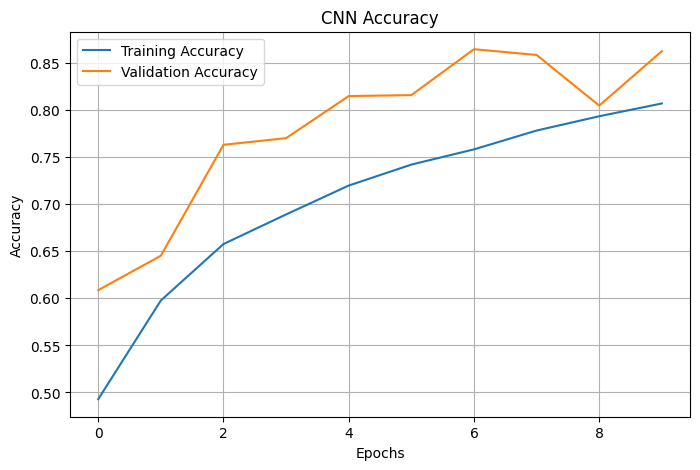

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('CNN Accuracy')
plt.legend()
plt.grid()
plt.show()

## Loss visualization

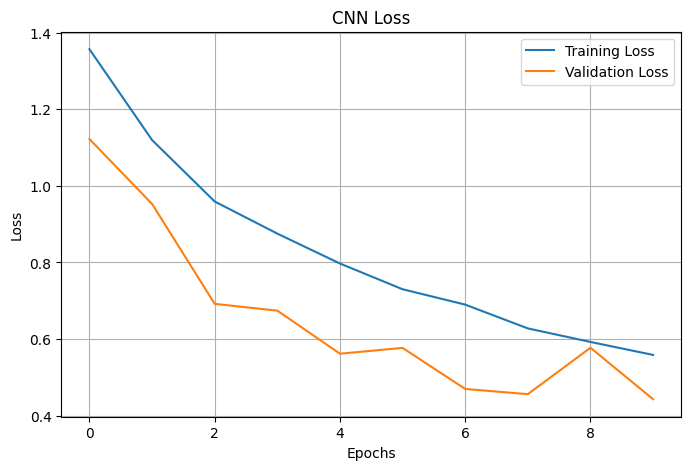

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('CNN Loss')
plt.legend()
plt.grid()
plt.show()

## Classification report

In [16]:
# Actual labels
ytrue = np.concatenate([labels.numpy() for images, labels in val_ds])
predictions = cnn.predict(val_ds, verbose=1) # Predicted probabilities
ypred = np.argmax(predictions, axis=1)    # Convert probabilities into class labels
print("Classification Report:\n")
print(classification_report(ytrue,ypred,labels=np.arange(num_classes),target_names=class_names,zero_division=0))

123/123 ━━━━━━━━━━━━━━━━━━━━ 8s 64ms/step
Classification Report:

                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.91      0.86      0.88       100
                        Tomato___Early_blight       0.86      0.91      0.88       100
                         Tomato___Late_blight       0.82      0.75      0.78       100
                           Tomato___Leaf_Mold       0.85      0.90      0.87       100
                  Tomato___Septoria_leaf_spot       0.87      0.73      0.79       100
Tomato___Spider_mites Two-spotted_spider_mite       0.74      0.93      0.82        84
                         Tomato___Target_Spot       0.90      0.72      0.80       100
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.78      0.97      0.87       100
                 Tomato___Tomato_mosaic_virus       0.96      1.00      0.98       100
                             Tomato___healthy       1.00      0

## Confusion matrix

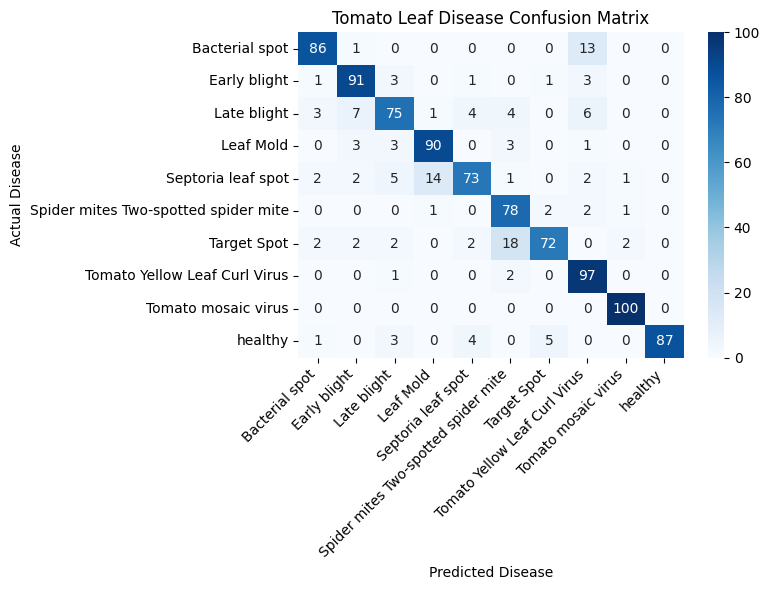

In [22]:
cm = confusion_matrix(ytrue,ypred,labels=np.arange(num_classes))
plt.figure(figsize=(8, 6))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=short_names,yticklabels=short_names)
plt.xlabel('Predicted Disease')
plt.ylabel('Actual Disease')
plt.title('Tomato Leaf Disease Confusion Matrix')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Predict using a new image 1

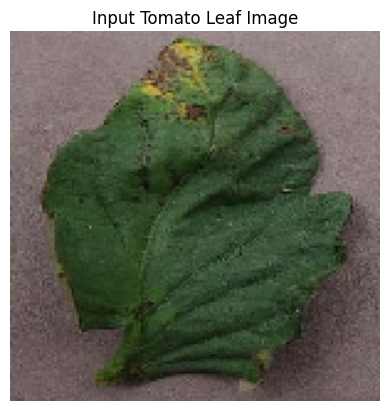

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
Predicted Disease: Tomato___Bacterial_spot
Confidence: 78.35 %


In [18]:
from tensorflow.keras.utils import load_img, img_to_array
img_path = '/content/bacterial_spot.JPG'
# Load RGB image
img = load_img(img_path,target_size=(150, 150),color_mode='rgb')
# Convert into array
img_array = img_to_array(img)
# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)
# Display image
plt.imshow(img)
plt.title("Input Tomato Leaf Image")
plt.axis('off')
plt.show()
# Predict
pred = cnn.predict(img_array)
predicted_output = np.argmax(pred, axis=1)
predicted_name = class_names[predicted_output[0]]
confidence = np.max(pred[0]) * 100
print("Predicted Disease:", predicted_name)
print("Confidence:", round(confidence, 2), "%")

## Predict using a new image 2

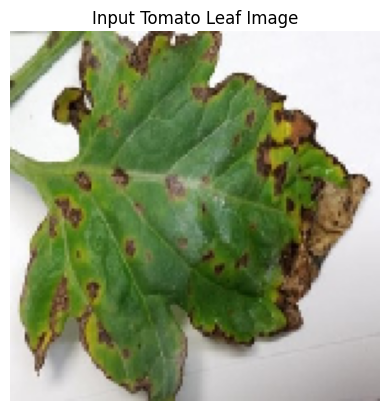

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
Predicted Disease: Tomato___Early_blight
Confidence: 92.74 %


In [19]:
img_path = '/content/tomato-septoria1.jpg'
img = load_img(img_path,target_size=(150, 150),color_mode='rgb')
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
plt.imshow(img)
plt.title("Input Tomato Leaf Image")
plt.axis('off')
plt.show()
pred = cnn.predict(img_array)
predicted_output = np.argmax(pred, axis=1)
predicted_name = class_names[predicted_output[0]]
confidence = np.max(pred[0]) * 100
print("Predicted Disease:", predicted_name)
print("Confidence:", round(confidence, 2), "%")

## Predict using a new image 3

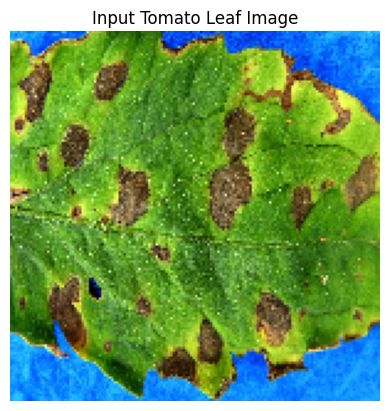

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
Predicted Disease: Tomato___Leaf_Mold
Confidence: 86.92 %


In [20]:
img_path = '/content/tmt_early_blight1.jpg'
img = load_img(img_path,target_size=(150, 150),color_mode='rgb')
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
plt.imshow(img)
plt.title("Input Tomato Leaf Image")
plt.axis('off')
plt.show()
pred = cnn.predict(img_array)
predicted_output = np.argmax(pred, axis=1)
predicted_name = class_names[predicted_output[0]]
confidence = np.max(pred[0]) * 100
print("Predicted Disease:", predicted_name)
print("Confidence:", round(confidence, 2), "%")